In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

real = pd.read_csv(
    "../data/processed/real_sensor_data.csv"
)

synthetic = pd.read_csv(
    "../data/processed/synthetic_sensor_data.csv"
)

In [2]:
features_to_compare = [
    "speed_rpm",
    "Current",
    "Voltage",
    "temp_mot",
    "temp_amb"
]

comparison = pd.DataFrame({
    "real_mean":
        real[features_to_compare].mean(),

    "synthetic_mean":
        synthetic[features_to_compare].mean(),

    "real_std":
        real[features_to_compare].std(),

    "synthetic_std":
        synthetic[features_to_compare].std()
})

comparison

,real_mean,synthetic_mean,real_std,synthetic_std
speed_rpm,8780.042676,8811.589521,1018.365344,1003.398461
Current,2.010838,2.045894,0.615758,0.583437
Voltage,3.824467,3.853498,0.998498,0.985442
temp_mot,44.700728,44.818802,12.681593,12.565632
temp_amb,21.974215,21.973544,0.187034,0.188237


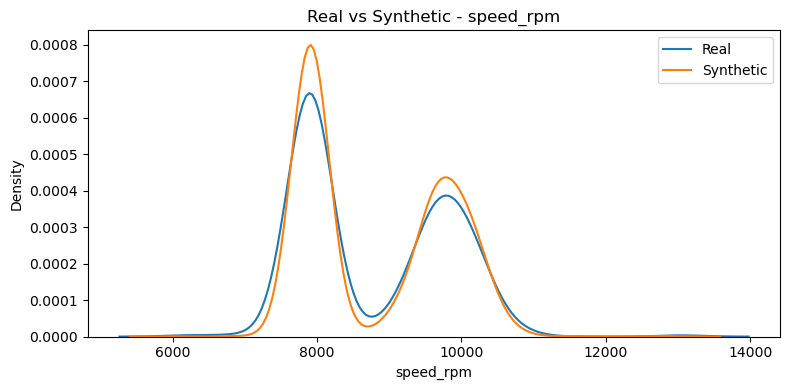

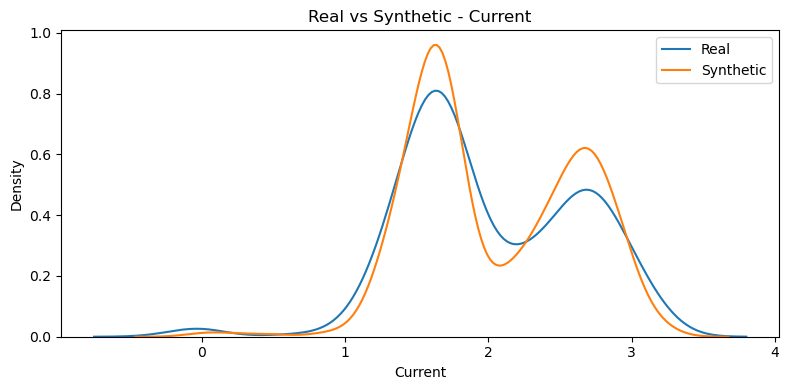

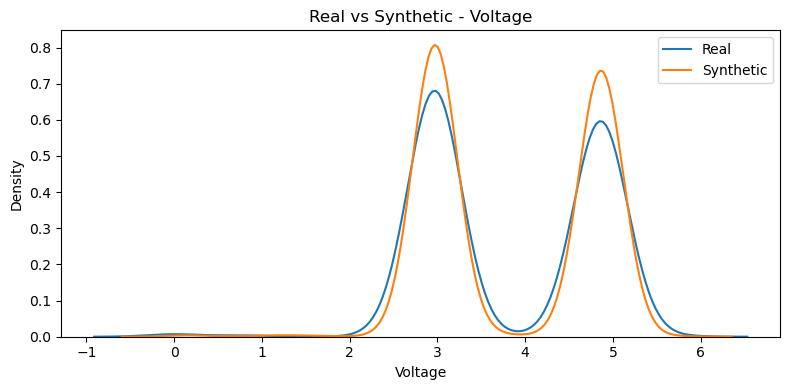

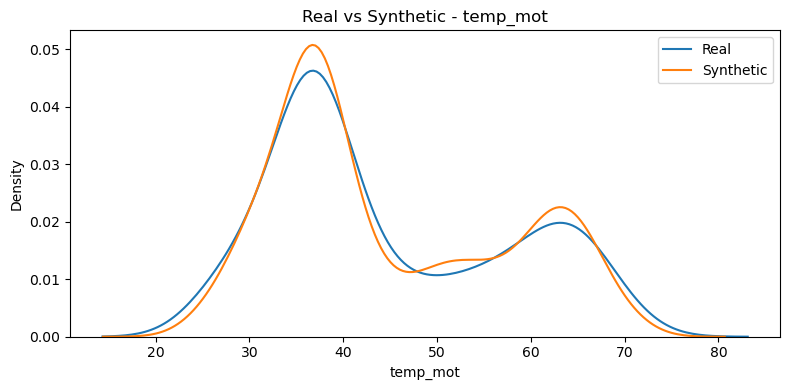

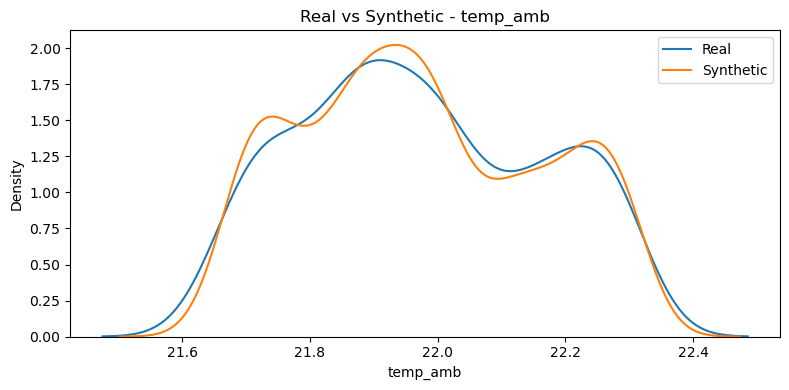

In [3]:
for column in features_to_compare:

    plt.figure(figsize=(8, 4))

    sns.kdeplot(
        real[column],
        label="Real"
    )

    sns.kdeplot(
        synthetic[column],
        label="Synthetic"
    )

    plt.title(
        f"Real vs Synthetic - {column}"
    )

    plt.legend()

    plt.tight_layout()
    plt.show()

In [4]:
real_corr = (
    real[features_to_compare]
    .corr()
)

synthetic_corr = (
    synthetic[features_to_compare]
    .corr()
)

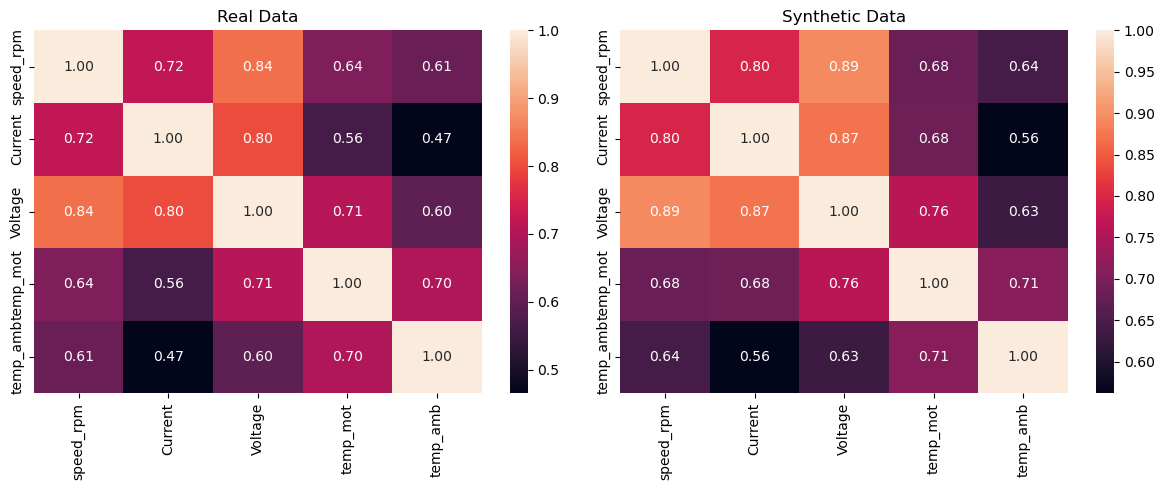

In [5]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

sns.heatmap(
    real_corr,
    annot=True,
    fmt=".2f",
    ax=axes[0]
)

axes[0].set_title("Real Data")

sns.heatmap(
    synthetic_corr,
    annot=True,
    fmt=".2f",
    ax=axes[1]
)

axes[1].set_title("Synthetic Data")

plt.tight_layout()
plt.show()

In [6]:
# min max check
for column in features_to_compare:
    real_min = real[column].min()
    real_max = real[column].max()
    synthetic_min = synthetic[column].min()
    synthetic_max = synthetic[column].max()

    print(
        f"{column}: Real Min: {real_min}, Real Max: {real_max}, "
        f"Synthetic Min: {synthetic_min}, Synthetic Max: {synthetic_max}"
    )

speed_rpm: Real Min: 6198.087563, Real Max: 13041.030144, Synthetic Min: 6013.559262651377, Synthetic Max: 12975.654742496608
Current: Real Min: -0.185699, Real Max: 3.235693, Synthetic Min: -0.1059345203736943, Synthetic Max: 3.322873482376103
Voltage: Real Min: 0.002189, Real Max: 5.616354, Synthetic Min: 0.0, Synthetic Max: 5.758703448211568
temp_mot: Real Min: 25.968306, Real Max: 71.51061, Synthetic Min: 21.996030917741574, Synthetic Max: 73.08115541877854
temp_amb: Real Min: 21.646436, Real Max: 22.314419, Synthetic Min: 21.61634011173297, Synthetic Max: 22.36041031262912


In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_real = real[features_to_compare].astype(float)
X_synthetic = synthetic[features_to_compare].astype(float)

# Fit scaler on real data only
scaler = StandardScaler()

X_real_scaled = scaler.fit_transform(X_real)
X_synthetic_scaled = scaler.transform(X_synthetic)

# Fit PCA on real data
pca = PCA(n_components=2)

real_pca = pca.fit_transform(X_real_scaled)
synthetic_pca = pca.transform(X_synthetic_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.73345472 0.12882807]


In [8]:
pca.fit(X_real_scaled)

PCA(n_components=2)

In [9]:
synthetic_pca = pca.transform(X_synthetic_scaled)

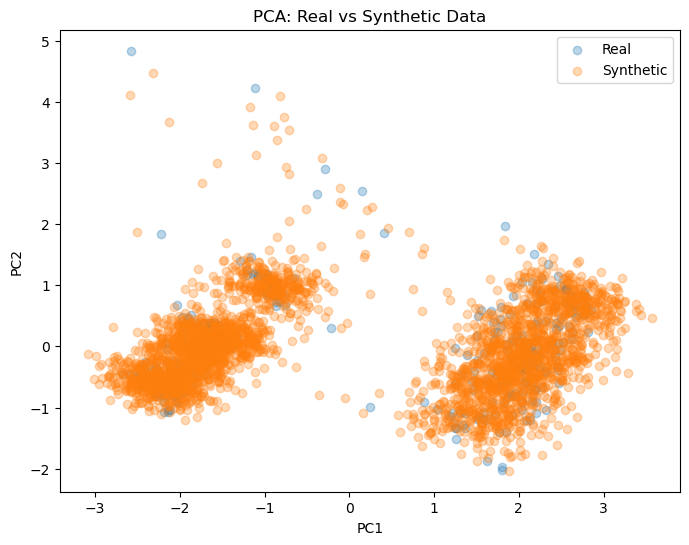

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    real_pca[:, 0],
    real_pca[:, 1],
    alpha=0.3,
    label="Real"
)

plt.scatter(
    synthetic_pca[:, 0],
    synthetic_pca[:, 1],
    alpha=0.3,
    label="Synthetic"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA: Real vs Synthetic Data")
plt.legend()
plt.show()

In [11]:
synthetic.shape

(3000, 50)

We generated synthetic sensor measurements using a neighbour-based interpolation approach. For each synthetic sample, we randomly selected a real observation and one of its nearest neighbours in standardized feature space. We interpolated between the two observations to generate a new point within the local operating regime. Then, we added multivariate correlated noise estimated from the real data using Ledoit-Wolf covariance estimation. Finally, we transformed the samples back to the original scale and applied physical consistency constraints.